# Modul 03 — Optimizer dan Strategi Pelatihan
**Nama:** Abdillah Fikri Alpome · **NIM:** 123450062 · **Kelas:** RC  
**Tanggal:** 2026-10-27 · **Seed data/model:** 62 · **Device:** CPU

Implementasi diadaptasi dengan izin dari notebook praktikum Fabio Banyu Cyto dan starter resmi DSWorkbench. Kode dan draf analisis dibantu OpenAI Codex; seluruh hasil berkas ini dihitung ulang pada NIM 123450062. Sumber: https://github.com/fabiobanyu/deep-learning-123450104 . Praktikan perlu memahami dan meninjau hasil sebelum pengumpulan.

In [1]:
import copy,hashlib,itertools,json,math,platform,random,time
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch,torchvision
from IPython.display import display,Markdown
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from torchvision.datasets import FashionMNIST

NAMA = 'Abdillah Fikri Alpome'
NIM = '123450062'
KELAS = 'RC'
SEED=int(NIM[-4:]); SEED_CARI=SEED+1
DEVICE=torch.device('cpu')
torch.set_num_threads(2); torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float32)
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything(SEED)
REPO=next(p for p in [Path('.'),*Path('.').resolve().parents] if (p/'templates/template-metrics.csv').is_file())
MOD=REPO/'notebooks/modul-03'; FIG=MOD/'figures'; SUPPORT=MOD/'hasil'
FIG.mkdir(parents=True,exist_ok=True); SUPPORT.mkdir(parents=True,exist_ok=True)
DATA_ROOT=REPO/'data/raw'; PREFIX=f'M03_{NIM}'
COLS=list(pd.read_csv(REPO/'templates/template-metrics.csv',nrows=0).columns)
ENV=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,torch=torch.__version__,torchvision=torchvision.__version__,device=str(DEVICE),seed=SEED,threads=torch.get_num_threads())
print(ENV)
RUNS=[]; HISTORY={}; MODELS={}; TEST_PASSES=0
def json_default(value):return value.item() if hasattr(value,'item') else str(value)
def save_progress():
    rows=[]
    for r in RUNS:
        notes={k:v for k,v in r.items() if k not in ['train_loss','val_loss','val_acc','test_acc','runtime_s']}
        rows.append(dict(run_id=r['run_id'],module='M03',student_id=NIM,seed=SEED,dataset='Fashion-MNIST',split='stratified train-validation-test',model=r['model'],optimizer=r['optimizer'],learning_rate=r['learning_rate'],batch_size=r['batch_size'],epochs=r['epochs_completed'],train_loss=r['train_loss'],val_loss=r['val_loss'],val_metric=r['val_acc'],test_metric=r.get('test_acc',''),parameters=r['parameters'],trainable_parameters=r['parameters'],runtime_seconds=r['runtime_s'],device=str(DEVICE),notes=json.dumps(notes,default=json_default,ensure_ascii=False)))
    pd.DataFrame(rows,columns=COLS).to_csv(MOD/f'{PREFIX}_metrics.csv',index=False)
    pd.DataFrame([dict(run_id=rid,**e) for rid,h in HISTORY.items() for e in h]).to_csv(SUPPORT/f'{PREFIX}_history.csv',index=False)
def show_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIG/name,dpi=160,bbox_inches='tight'); plt.show()


{'python': '3.14.7', 'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.14.0+cpu', 'torchvision': '0.29.0+cpu', 'device': 'cpu', 'seed': 62, 'threads': 2}


## A. Pre-lab dan prediksi sebelum menjalankan
1. Satu epoch membutuhkan ceil(12000/128)=94 update; lima epoch 470 update.
2. Mini-batch memberikan perkiraan gradien yang berubah sesuai contoh yang dipilih; full-batch memakai semua contoh sehingga tidak memiliki derau pemilihan mini-batch.
3. Skala pembaruan SGD dan Adam berbeda karena Adam menyesuaikan momen gradien; LR yang sama bukan jaminan perbandingan adil.
4. LR sepuluh kali lebih besar diperkirakan memberi penurunan cepat tetapi berisiko berosilasi atau divergen.

**Hipotesis sebelum run:** Adam diperkirakan mencapai loss validasi rendah lebih cepat daripada SGD pada lima epoch. Scheduler mungkin belum membantu karena anggaran pendek. Batch 32 diperkirakan memberi loss lebih rendah melalui lebih banyak update, tetapi lebih lama daripada batch 512; prediksi akan dibandingkan dengan angka aktual.

Anggaran tetap: subset 12000/3000, FNN 784–128–10, batch utama 128, lima epoch. Semua run melewati fungsi yang sama dengan seed data, bobot, dan loader diulang. Model final dipilih berdasarkan loss validasi epoch kelima dari sembilan run inti dan enam run tambahan; test dibuka sesudah semua keputusan. Tiga baseline LR dicatat sebagai eksplorasi terpisah.

In [2]:
prediction=dict(written_at=datetime.now().isoformat(timespec='seconds'),seed=SEED,seed_search=SEED_CARI,
    text="Adam diperkirakan lebih cepat menurunkan loss; batch 32 lebih banyak update dan lebih lambat daripada batch 512; scheduler belum tentu membantu pada lima epoch.")
(SUPPORT/'prediksi-sebelum-run.json').write_text(json.dumps(prediction,ensure_ascii=False,indent=2),encoding='utf-8')
full_train=FashionMNIST(root=DATA_ROOT,train=True,download=False)
labels=full_train.targets.numpy()
idx_train,idx_val=train_test_split(np.arange(len(labels)),train_size=12000,test_size=3000,stratify=labels,random_state=SEED)
assert not set(idx_train)&set(idx_val)
Xtrain=full_train.data[idx_train].float().unsqueeze(1)/255.0
Xval=full_train.data[idx_val].float().unsqueeze(1)/255.0
MEAN,STD=Xtrain.mean(),Xtrain.std()
assert STD>0
ds_latih=TensorDataset((Xtrain-MEAN)/STD,full_train.targets[idx_train])
ds_val=TensorDataset((Xval-MEAN)/STD,full_train.targets[idx_val])
assert len(ds_latih)==12000 and len(ds_val)==3000
assert np.bincount(labels[idx_train]).min()==1200
manifest=pd.concat([pd.DataFrame(dict(index=idx_train,label=labels[idx_train],split='train')),pd.DataFrame(dict(index=idx_val,label=labels[idx_val],split='validation'))])
manifest.to_csv(SUPPORT/'split-manifest.csv',index=False)
def normalkan(x):return (x-MEAN)/STD
def loader(ds,batch,acak=False):
    return DataLoader(ds,batch_size=batch,shuffle=acak,generator=torch.Generator().manual_seed(SEED),num_workers=0)
@torch.no_grad()
def evaluasi(model,ds):
    model.eval(); loss_sum=correct=0
    for x,y in loader(ds,512):
        x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x)
        loss_sum+=nn.functional.cross_entropy(logits,y,reduction='sum').item()
        correct+=(logits.argmax(1)==y).sum().item()
    return loss_sum/len(ds),correct/len(ds)
print('Train/validation:',len(ds_latih),len(ds_val),'mean/std:',float(MEAN),float(STD))
print('Kelas train:',np.bincount(labels[idx_train]).tolist())


Train/validation: 12000 3000 mean/std: 0.28656765818595886 0.35334283113479614
Kelas train: [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200]


In [3]:
BATCH,EPOCH=128,5
def buat_model():
    seed_everything(SEED)
    return nn.Sequential(nn.Flatten(),nn.Linear(784,128),nn.ReLU(),nn.Linear(128,10)).to(DEVICE)
assert sum(p.numel() for p in buat_model().parameters())==101770
def jalankan(nama_opt,lr,batch=BATCH,epoch=EPOCH,scheduler=None,label=None,group='grid'):
    model=buat_model()
    if nama_opt=='sgd':opt=torch.optim.SGD(model.parameters(),lr=lr)
    elif nama_opt=='momentum':opt=torch.optim.SGD(model.parameters(),lr=lr,momentum=.9)
    elif nama_opt=='adam':opt=torch.optim.Adam(model.parameters(),lr=lr)
    else:raise ValueError(nama_opt)
    sch=None
    if scheduler=='step':sch=torch.optim.lr_scheduler.StepLR(opt,step_size=2,gamma=.5)
    elif scheduler=='cosine':sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epoch)
    rid=label or f'{group}_{nama_opt}_{lr:g}_{scheduler}_{batch}'
    assert rid not in HISTORY
    train_loader=loader(ds_latih,batch,True)
    norms=[]; history=[]; updates=0; status='ok'; started=time.perf_counter()
    for e in range(1,epoch+1):
        model.train(); total_loss=seen=0; e_start=time.perf_counter()
        for x,y in train_loader:
            x,y=x.to(DEVICE),y.to(DEVICE);opt.zero_grad(set_to_none=True)
            loss=nn.functional.cross_entropy(model(x),y)
            if not torch.isfinite(loss):status=f'failed_nonfinite_epoch_{e}';break
            loss.backward()
            norms.append(math.sqrt(sum(p.grad.detach().norm().item()**2 for p in model.parameters() if p.grad is not None)))
            opt.step();updates+=1;total_loss+=loss.item()*len(y);seen+=len(y)
        if not seen:break
        va,acc=evaluasi(model,ds_val)
        tr,tr_acc=evaluasi(model,ds_latih)
        history.append(dict(epoch=e,train_loss=tr,train_acc=tr_acc,online_train_loss=total_loss/seen,val_loss=va,val_acc=acc,learning_rate=opt.param_groups[0]['lr'],seconds=time.perf_counter()-e_start))
        if sch:sch.step()
        print(f'[{rid}] epoch {e}/{epoch} train={tr:.5f} val={va:.5f} acc={acc:.4f}',flush=True)
        if status!='ok':break
    assert history,'Tidak ada epoch valid'
    r=dict(run_id=rid,optimizer=nama_opt,learning_rate=lr,scheduler=scheduler or 'none',batch_size=batch,epochs_planned=epoch,epochs_completed=len(history),n_update=updates,parameters=101770,model='FNN(784-128-10)',train_loss=tr,train_acc=tr_acc,val_loss=va,val_acc=acc,grad_norm_mean=float(np.mean(norms)),runtime_s=time.perf_counter()-started,status=status,group=group)
    r['runtime_per_epoch_s']=r['runtime_s']/len(history)
    RUNS.append(r);HISTORY[rid]=history;MODELS[rid]=copy.deepcopy(model.state_dict());save_progress()
    return r
print('Parameter:',101770)


Parameter: 101770


[baseline_sgd_lr0.001] epoch 1/5 train=2.03739 val=2.03921 acc=0.3813


[baseline_sgd_lr0.001] epoch 2/5 train=1.81826 val=1.82067 acc=0.5573


[baseline_sgd_lr0.001] epoch 3/5 train=1.62566 val=1.62877 acc=0.6167


[baseline_sgd_lr0.001] epoch 4/5 train=1.46582 val=1.46987 acc=0.6363


[baseline_sgd_lr0.001] epoch 5/5 train=1.33679 val=1.34181 acc=0.6553


...

[baseline_sgd_lr1] epoch 1/5 train=1.86859 val=1.87006 acc=0.3027


[baseline_sgd_lr1] epoch 2/5 train=1.74680 val=1.76431 acc=0.3423


[baseline_sgd_lr1] epoch 3/5 train=1.88489 val=1.89577 acc=0.2693


[baseline_sgd_lr1] epoch 4/5 train=2.04570 val=2.09624 acc=0.2163


[baseline_sgd_lr1] epoch 5/5 train=1.75473 val=1.79417 acc=0.3257


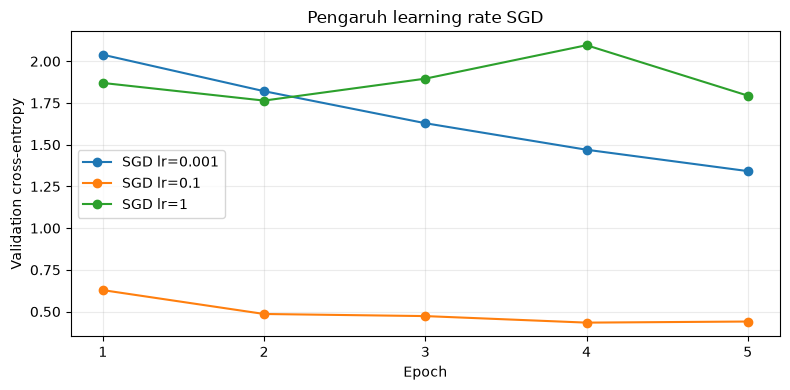

,run_id,optimizer,learning_rate,scheduler,batch_size,epochs_planned,epochs_completed,n_update,parameters,model,train_loss,train_acc,val_loss,val_acc,grad_norm_mean,runtime_s,status,group,runtime_per_epoch_s
0,baseline_sgd_lr0.001,sgd,0.001,none,128,5,5,470,101770,FNN(784-128-10),1.336788,0.669917,1.341808,0.655333,1.741598,1.460531,ok,baseline,0.292106
1,baseline_sgd_lr0.1,sgd,0.100,none,128,5,5,470,101770,FNN(784-128-10),0.384780,0.859417,0.440400,0.839000,1.335649,1.458667,ok,baseline,0.291733
2,baseline_sgd_lr1,sgd,1.000,none,128,5,5,470,101770,FNN(784-128-10),1.754734,0.326750,1.794175,0.325667,1.348454,1.394865,ok,baseline,0.278973


In [4]:
baseline=[]
for lr in [.001,.1,1.0]:baseline.append(jalankan('sgd',lr,label=f'baseline_sgd_lr{lr:g}',group='baseline'))
fig,ax=plt.subplots(figsize=(8,4))
for r in baseline:
    h=HISTORY[r['run_id']];ax.plot([e['epoch'] for e in h],[e['val_loss'] for e in h],marker='o',label=f"SGD lr={r['learning_rate']:g}")
ax.set(title='Pengaruh learning rate SGD',xlabel='Epoch',ylabel='Validation cross-entropy',xticks=range(1,6));ax.legend();ax.grid(alpha=.25)
show_figure(fig,'baseline-lr.png')
display(pd.DataFrame(baseline))


[grid_sgd_lr0.01] epoch 1/5 train=0.98853 val=0.99400 acc=0.7087


[grid_sgd_lr0.01] epoch 2/5 train=0.76724 val=0.77217 acc=0.7410


[grid_sgd_lr0.01] epoch 3/5 train=0.68191 val=0.68722 acc=0.7613


[grid_sgd_lr0.01] epoch 4/5 train=0.63491 val=0.64162 acc=0.7730


[grid_sgd_lr0.01] epoch 5/5 train=0.59448 val=0.60257 acc=0.7927


...

[grid_adam_lr0.01] epoch 2/5 train=0.47598 val=0.54647 acc=0.8033


[grid_adam_lr0.01] epoch 3/5 train=0.37678 val=0.46615 acc=0.8417


[grid_adam_lr0.01] epoch 4/5 train=0.34358 val=0.43042 acc=0.8513


[grid_adam_lr0.01] epoch 5/5 train=0.34950 val=0.45634 acc=0.8383


,run_id,optimizer,learning_rate,scheduler,batch_size,epochs_planned,epochs_completed,n_update,parameters,model,train_loss,train_acc,val_loss,val_acc,grad_norm_mean,runtime_s,status,group,runtime_per_epoch_s
0,grid_sgd_lr0.1,sgd,0.100,none,128,5,5,470,101770,FNN(784-128-10),0.384780,0.859417,0.440400,0.839000,1.335649,1.495457,ok,grid,0.299091
1,grid_momentum_lr0.05,momentum,0.050,none,128,5,5,470,101770,FNN(784-128-10),0.306223,0.887917,0.415501,0.852333,1.164492,1.518318,ok,grid,0.303664
2,grid_adam_lr0.001,adam,0.001,none,128,5,5,470,101770,FNN(784-128-10),0.327574,0.879000,0.405731,0.857667,1.536540,1.623522,ok,grid,0.324704


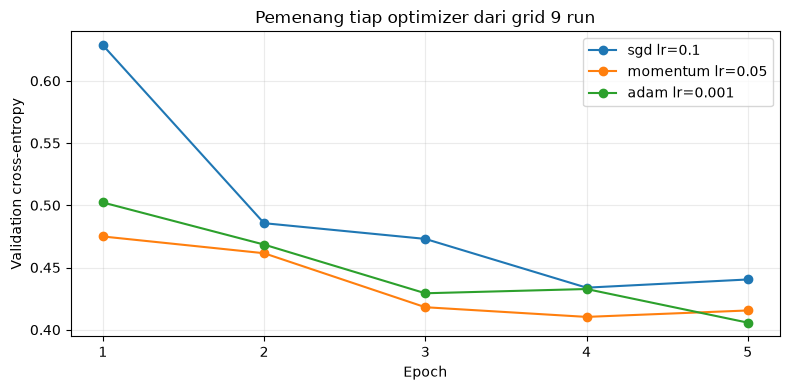

Optimizer/LR untuk tahap berikut: adam 0.001


In [5]:
GRID={'sgd':[.01,.1,.5],'momentum':[.01,.05,.1],'adam':[1e-4,1e-3,1e-2]}
core=[]
for opt,lrs in GRID.items():
    for lr in lrs:core.append(jalankan(opt,lr,label=f'grid_{opt}_lr{lr:g}'))
assert len(core)==9
winners=[min([r for r in core if r['optimizer']==name],key=lambda r:r['val_loss']) for name in GRID]
best_core=min(winners,key=lambda r:r['val_loss'])
display(pd.DataFrame(winners))
fig,ax=plt.subplots(figsize=(8,4))
for r in winners:
    h=HISTORY[r['run_id']];ax.plot([e['epoch'] for e in h],[e['val_loss'] for e in h],marker='o',label=f"{r['optimizer']} lr={r['learning_rate']:g}")
ax.set(title='Pemenang tiap optimizer dari grid 9 run',xlabel='Epoch',ylabel='Validation cross-entropy',xticks=range(1,6));ax.legend();ax.grid(alpha=.25)
show_figure(fig,'pemenang-optimizer.png')
print('Optimizer/LR untuk tahap berikut:',best_core['optimizer'],best_core['learning_rate'])


## F. Enam run tambahan dan latihan batch
Tiga kondisi scheduler (none/StepLR/Cosine) dan tiga batch (32/128/512) memakai optimizer/LR pemenang grid. Konfigurasi none-batch128 dijalankan pada dua kelompok karena menjadi kontrol masing-masing; keduanya dicatat, bukan disembunyikan. Prediksi latihan sudah ditulis pada A: batch kecil memiliki lebih banyak update, belum tentu lebih hemat waktu. Test masih belum diakses.

[scheduler_none] epoch 1/5 train=0.48198 val=0.50226 acc=0.8307


[scheduler_none] epoch 2/5 train=0.42926 val=0.46843 acc=0.8310


[scheduler_none] epoch 3/5 train=0.37689 val=0.42932 acc=0.8457


[scheduler_none] epoch 4/5 train=0.37035 val=0.43273 acc=0.8407


[scheduler_none] epoch 5/5 train=0.32757 val=0.40573 acc=0.8577


...

[batch_512] epoch 2/5 train=0.51286 val=0.53221 acc=0.8123


[batch_512] epoch 3/5 train=0.46189 val=0.48672 acc=0.8277


[batch_512] epoch 4/5 train=0.42864 val=0.45876 acc=0.8360


[batch_512] epoch 5/5 train=0.40642 val=0.44286 acc=0.8480


,run_id,optimizer,learning_rate,scheduler,batch_size,epochs_planned,epochs_completed,n_update,parameters,model,train_loss,train_acc,val_loss,val_acc,grad_norm_mean,runtime_s,status,group,runtime_per_epoch_s
0,scheduler_none,adam,0.001,none,128,5,5,470,101770,FNN(784-128-10),0.327574,0.879000,0.405731,0.857667,1.536540,1.613890,ok,scheduler,0.322778
1,scheduler_step,adam,0.001,step,128,5,5,470,101770,FNN(784-128-10),0.342786,0.879833,0.399626,0.858000,1.456916,1.619566,ok,scheduler,0.323913
2,scheduler_cosine,adam,0.001,cosine,128,5,5,470,101770,FNN(784-128-10),0.349977,0.877667,0.403414,0.856333,1.451892,1.622387,ok,scheduler,0.324477
3,batch_32,adam,0.001,none,32,5,5,1875,101770,FNN(784-128-10),0.284606,0.893417,0.396995,0.857000,2.290468,2.827100,ok,batch,0.565420
4,batch_128,adam,0.001,none,128,5,5,470,101770,FNN(784-128-10),0.327574,0.879000,0.405731,0.857667,1.536540,1.670341,ok,batch,0.334068
5,batch_512,adam,0.001,none,512,5,5,120,101770,FNN(784-128-10),0.406424,0.853333,0.442860,0.848000,1.081541,1.341366,ok,batch,0.268273


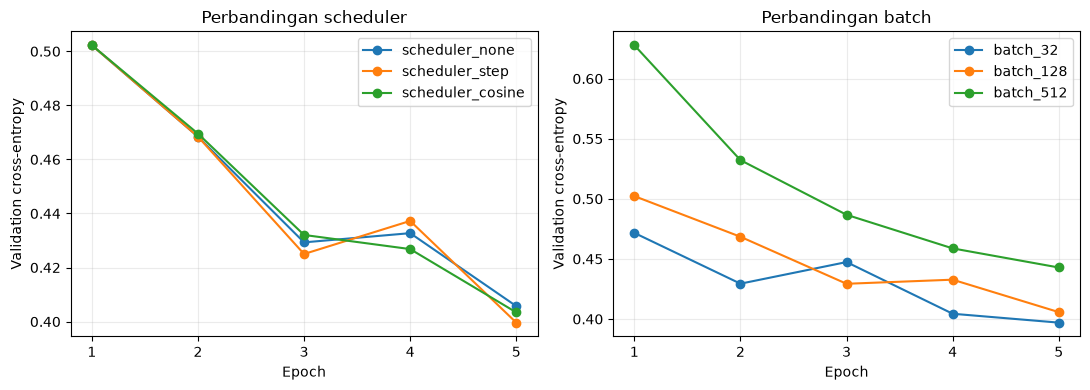

Model dipilih sebelum test: batch_32 0.3969949289957682


In [6]:
extras=[]
for sch in [None,'step','cosine']:
    extras.append(jalankan(best_core['optimizer'],best_core['learning_rate'],scheduler=sch,label=f'scheduler_{sch or "none"}',group='scheduler'))
for batch in [32,128,512]:
    extras.append(jalankan(best_core['optimizer'],best_core['learning_rate'],batch=batch,label=f'batch_{batch}',group='batch'))
assert len(extras)==6
assert next(r for r in extras if r['run_id']=='batch_32')['n_update']==1875
assert next(r for r in extras if r['run_id']=='batch_512')['n_update']==120
display(pd.DataFrame(extras))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,group in zip(axs,['scheduler','batch']):
    for r in extras:
        if r['group']!=group:continue
        h=HISTORY[r['run_id']];ax.plot([e['epoch'] for e in h],[e['val_loss'] for e in h],marker='o',label=r['run_id'])
    ax.set(title=f'Perbandingan {group}',xlabel='Epoch',ylabel='Validation cross-entropy',xticks=range(1,6));ax.legend();ax.grid(alpha=.25)
show_figure(fig,'scheduler-batch.png')
final=min(core+extras,key=lambda r:r['val_loss'])
final_model=buat_model(); final_model.load_state_dict(MODELS[final['run_id']])
assert len(RUNS)==18
print('Model dipilih sebelum test:',final['run_id'],final['val_loss'])


## Evaluasi akhir: satu lintasan test
Seluruh konfigurasi dikunci berdasarkan validation loss. Dataset test resmi baru dibuka di bawah; loss, accuracy dan confusion matrix dihitung dari satu koleksi logits yang sama, bukan beberapa evaluasi terpisah. Tidak ada tuning setelah melihat hasil test.

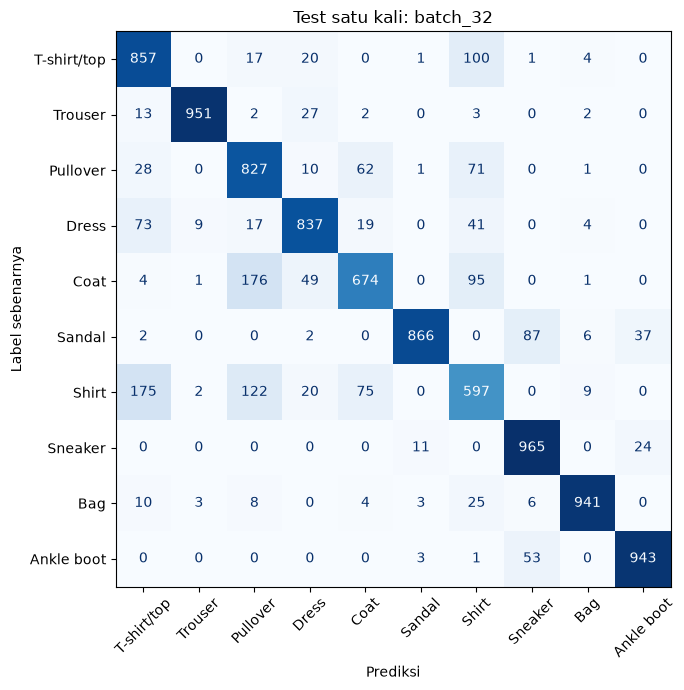

FINAL: batch_32 test_loss= 0.43150809020996095 test_acc= 0.8458 test_passes= 1


In [7]:
assert TEST_PASSES==0
TEST_PASSES+=1
official_test=FashionMNIST(root=DATA_ROOT,train=False,download=False)
Xt=normalkan(official_test.data.float().unsqueeze(1)/255.)
ds_uji=TensorDataset(Xt,official_test.targets)
@torch.no_grad()
def test_once(model):
    model.eval();loss_sum=0;truth=[];pred=[]
    for x,y in loader(ds_uji,512):
        x,y=x.to(DEVICE),y.to(DEVICE);logits=model(x)
        loss_sum+=nn.functional.cross_entropy(logits,y,reduction='sum').item()
        truth.extend(y.cpu().tolist());pred.extend(logits.argmax(1).cpu().tolist())
    return loss_sum/len(ds_uji),np.array(truth),np.array(pred)
test_loss,truth,pred=test_once(final_model)
test_acc=float((truth==pred).mean());final['test_acc']=test_acc
cm=confusion_matrix(truth,pred,labels=range(10))
CLASS_NAMES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
fig,ax=plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
ax.set(title='Test satu kali: '+final['run_id'],xlabel='Prediksi',ylabel='Label sebenarnya')
show_figure(fig,'confusion-test.png')
pd.DataFrame(dict(index=np.arange(len(truth)),true=truth,predicted=pred)).to_csv(SUPPORT/'test-predictions.csv',index=False)
save_progress()
summary=dict(name=NAMA,nim=NIM,class_name=KELAS,date=datetime.now().date().isoformat(),environment=ENV,seed=SEED,seed_search=SEED_CARI,normalization=dict(mean=float(MEAN),std=float(STD)),split=dict(train=len(ds_latih),validation=len(ds_val),test=len(ds_uji)),prediction=prediction,runs=RUNS,selected_run=final['run_id'],test_loss=test_loss,test_accuracy=test_acc,test_passes=TEST_PASSES,confusion_matrix=cm.tolist())
(SUPPORT/f'{PREFIX}_results.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=json_default),encoding='utf-8')
print('FINAL:',final['run_id'],'test_loss=',test_loss,'test_acc=',test_acc,'test_passes=',TEST_PASSES)
assert TEST_PASSES==1 and cm.sum()==10000


## Catatan interpretasi dan reproduksi
Semua angka tersedia pada metrics dan hasil/riwayat per epoch. Seluruh run, termasuk konfigurasi buruk, tetap dicatat. Template 20 kolom dipertahankan; hyperparameter tambahan, jumlah update, status, gradien atau gap disimpan pada notes JSON. Laporan dan latihan pendamping disusun dari hasil aktual, dengan prediksi yang tercatat sebelum training.

Referensi: materi dan starter resmi DSWorkbench; adaptasi notebook Fabio Banyu Cyto dengan izin; dokumentasi PyTorch optimizers dan torchvision FashionMNIST. Bantuan OpenAI Codex dicantumkan untuk implementasi dan draf pembahasan. Praktikan meninjau hasil dan pernyataan orisinalitas sebelum pengumpulan.

## Pembahasan berdasarkan eksekusi ini

**1.** Model grid terbaik adalah grid_adam_lr0.001 dengan validation loss 0.405731 dan runtime 1.62 detik. Run tercepat adalah grid_sgd_lr0.5 dengan waktu 1.41 detik dan loss 0.540700; loss terendah dan waktu tercepat mengukur tujuan berbeda.

**2.** Adam terbaik memakai LR 0.001, sedangkan SGD terbaik LR 0.1. Adam membagi momen pertama gradien dengan skala momen keduanya, sehingga nilai learning rate numerik yang sama tidak memberikan besar pembaruan yang sama seperti SGD.

**3.** Pada baseline SGD LR 1, validation loss akhir 1.794175 dan grad_norm_mean 1.348454. Kenaikan loss antar-epoch pertama teramati pada epoch 3; langkah terlalu besar dapat melewati daerah minimum dan menghasilkan osilasi.

**4.** Tanpa scheduler diperoleh loss 0.405731; StepLR 0.399626; CosineAnnealingLR 0.403414, semuanya lima epoch. Scheduler tidak menjamin perbaikan: penurunan LR terlalu awal dapat membatasi langkah optimisasi ketika model belum cukup belajar.

**5.** Jika efisiensi diukur sebagai validation accuracy dibagi runtime pada run lima epoch yang tersedia, batch 512 paling tinggi: accuracy 0.8480, waktu 1.34 detik, dan 120 update. Ini rekomendasi berdasarkan ukuran pendekatan efisiensi, bukan bukti pada eksperimen dengan batas waktu persis sama.